# Weed Detection in Crops Using YOLO and CNN

## Machine Learning Project

### Objective
To detect weeds in crop images using YOLO-based object detection and CNN-based image classification.

### Dataset
The dataset contains agricultural images with crop and weed annotations.

### Classes
- Crop
- Weed

In [6]:
%pip install numpy pandas matplotlib

  Using cached pandas-3.0.5-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---- ----------------------------------- 1.6/12.7 MB 7.1 MB/s eta 0:00:02
   --------- ------------------------------ 3.1/12.7 MB 7.5 MB/s eta 0:00:02
   -------------- ------------------------- 4.7/12.7 MB 7.4 MB/s eta 0:00:02
   ------------------- -------------------- 6.3/12.7 MB 7.4 MB/s eta 0:00:01
   ------------------------ --------------- 7.9/12.7 MB 7.4 MB/s eta 0:00:01
   ----------------------------- ---------- 9.4/12.7 MB 7.3 MB/s eta 0:00:01
   ---------------------------------- ----- 11.0/12.7 MB 7.3 MB/s eta 0:00:01
   ---------------------------------------  12.6/12.7 MB 7.3 MB/s eta 0:00:01
   -----------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

print("\nProject folder:", os.getcwd())

Python version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
NumPy version: 2.5.3
Pandas version: 3.0.5

Project folder: c:\Users\sunee\OneDrive\Desktop\Weed_Detection_Project\notebook


In [9]:
import os

dataset_path = "../dataset"

print("Dataset contents:")
print(os.listdir(dataset_path))

Dataset contents:
['agri_data', 'classes.txt']


In [10]:
data_path = "../dataset/agri_data/data"

files = os.listdir(data_path)

image_files = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
label_files = [f for f in files if f.lower().endswith(".txt")]

print("Total files:", len(files))
print("Total images:", len(image_files))
print("Total annotation files:", len(label_files))

print("\nFirst 5 images:")
print(image_files[:5])

print("\nFirst 5 annotation files:")
print(label_files[:5])

Total files: 2600
Total images: 1300
Total annotation files: 1300

First 5 images:
['agri_0_1009.jpeg', 'agri_0_1017.jpeg', 'agri_0_1018.jpeg', 'agri_0_1020.jpeg', 'agri_0_1024.jpeg']

First 5 annotation files:
['agri_0_1009.txt', 'agri_0_1017.txt', 'agri_0_1018.txt', 'agri_0_1020.txt', 'agri_0_1024.txt']


In [11]:
classes_path = "../dataset/classes.txt"

with open(classes_path, "r") as f:
    classes = [line.strip() for line in f if line.strip()]

print("Classes:")
for i, name in enumerate(classes):
    print(i, "→", name)

Classes:
0 → crop
1 → weed


In [12]:
image_names = {
    os.path.splitext(f)[0]
    for f in image_files
}

label_names = {
    os.path.splitext(f)[0]
    for f in label_files
}

images_without_labels = image_names - label_names
labels_without_images = label_names - image_names

print("Images without annotation files:", len(images_without_labels))
print("Annotations without images:", len(labels_without_images))

if len(images_without_labels) == 0 and len(labels_without_images) == 0:
    print("All images have corresponding annotation files.")

Images without annotation files: 0
Annotations without images: 0
All images have corresponding annotation files.


In [13]:
valid_labels = 0
invalid_labels = 0
class_counts = {i: 0 for i in range(len(classes))}

for label_file in label_files:
    label_path = os.path.join(data_path, label_file)

    with open(label_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    file_valid = True

    for line in lines:
        values = line.split()

        if len(values) != 5:
            file_valid = False
            continue

        try:
            class_id = int(values[0])
            coordinates = list(map(float, values[1:]))

            if class_id not in class_counts:
                file_valid = False
                continue

            if not all(0 <= x <= 1 for x in coordinates):
                file_valid = False
                continue

            class_counts[class_id] += 1

        except ValueError:
            file_valid = False

    if file_valid:
        valid_labels += 1
    else:
        invalid_labels += 1

print("Valid annotation files:", valid_labels)
print("Invalid annotation files:", invalid_labels)

print("\nAnnotation class counts:")
for class_id, count in class_counts.items():
    print(f"{class_id} → {classes[class_id]}: {count}")

Valid annotation files: 1300
Invalid annotation files: 0

Annotation class counts:
0 → crop: 1212
1 → weed: 860


In [14]:
from collections import Counter

image_name_counts = Counter(
    os.path.splitext(f)[0] for f in image_files
)

duplicate_names = {
    name: count
    for name, count in image_name_counts.items()
    if count > 1
}

print("Duplicate image names:", len(duplicate_names))

if len(duplicate_names) == 0:
    print("No duplicate image names were found.")

Duplicate image names: 0
No duplicate image names were found.


## 3. Exploratory Data Analysis (EDA)

### 3.1 Class Distribution

The distribution of crop and weed annotations is analyzed to understand whether the dataset is balanced across the two target classes.

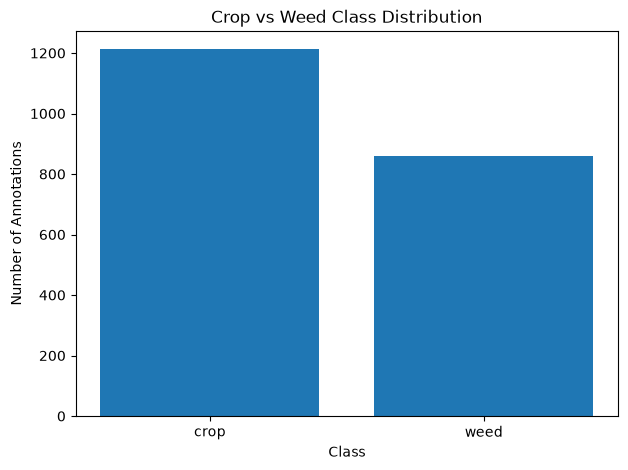

In [15]:
import matplotlib.pyplot as plt

class_names = [classes[i] for i in sorted(class_counts.keys())]
class_values = [class_counts[i] for i in sorted(class_counts.keys())]

plt.figure(figsize=(7, 5))
plt.bar(class_names, class_values)
plt.xlabel("Class")
plt.ylabel("Number of Annotations")
plt.title("Crop vs Weed Class Distribution")
plt.show()

### Observation

The bar chart shows the number of annotations belonging to each class. This helps identify whether crop and weed samples are balanced or whether one class has more annotations than the other.

### 3.2 Sample Images

Random/sample images from the dataset are visualized to understand the appearance and variation of crop and weed regions.

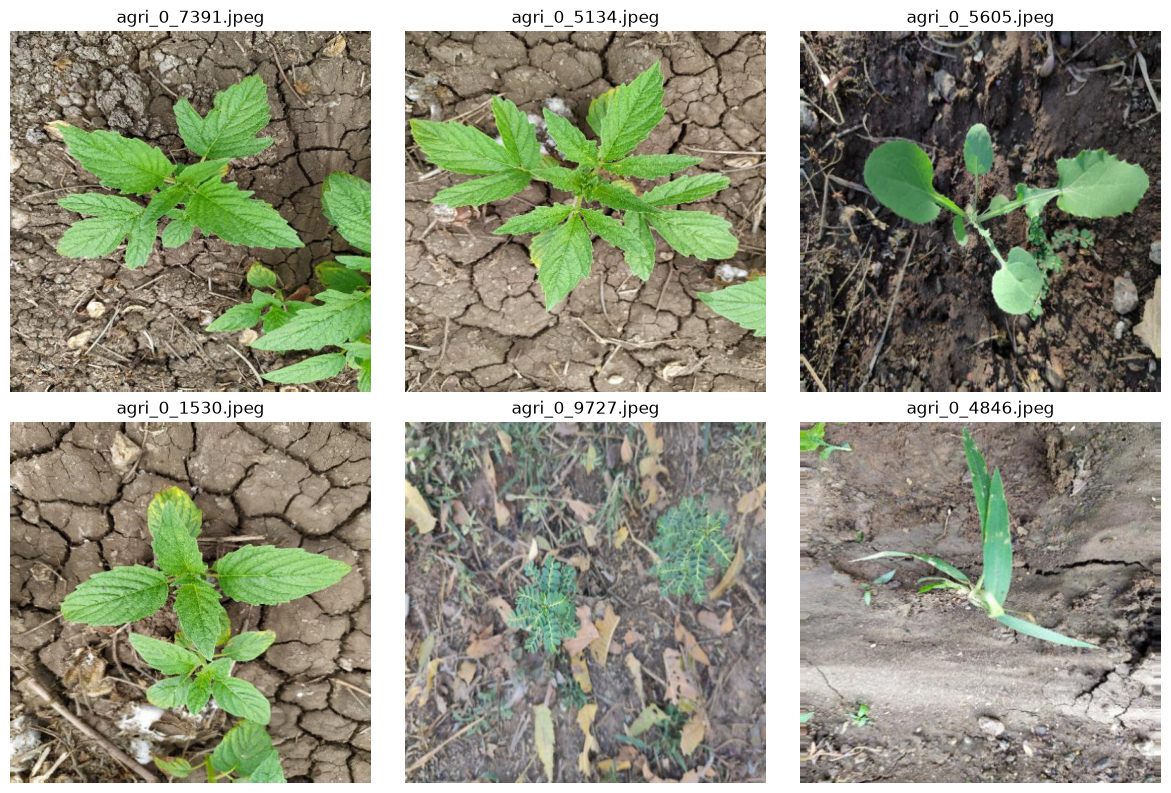

In [16]:
from PIL import Image
import random

sample_images = random.sample(image_files, min(6, len(image_files)))

plt.figure(figsize=(12, 8))

for i, image_file in enumerate(sample_images):
    image_path = os.path.join(data_path, image_file)
    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_file)
    plt.axis("off")

plt.tight_layout()
plt.show()

### 3.3 Image Dimensions

The dimensions of the images are analyzed to understand the variation in image resolution before model training.

In [17]:
from PIL import Image
from collections import Counter

dimensions = []

for image_file in image_files:
    image_path = os.path.join(data_path, image_file)

    try:
        with Image.open(image_path) as img:
            dimensions.append(img.size)
    except Exception:
        pass

dimension_counts = Counter(dimensions)

print("Number of images successfully analyzed:", len(dimensions))
print("\nMost common image dimensions:")

for dimension, count in dimension_counts.most_common(10):
    print(dimension, "→", count, "images")

Number of images successfully analyzed: 1300

Most common image dimensions:
(512, 512) → 1300 images


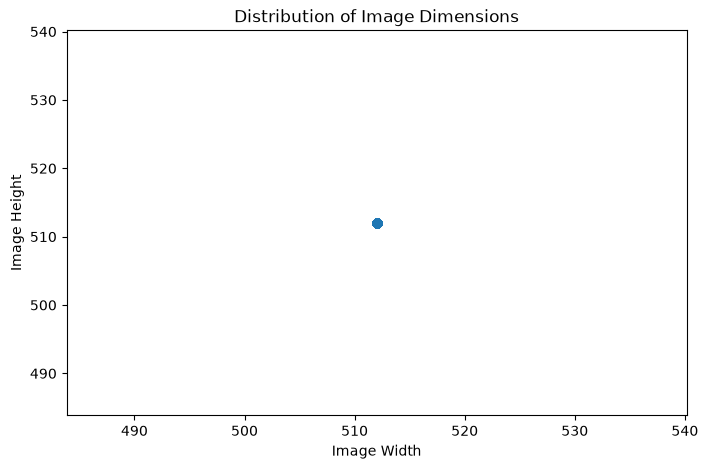

In [18]:
widths = [w for w, h in dimensions]
heights = [h for w, h in dimensions]

plt.figure(figsize=(8, 5))
plt.scatter(widths, heights, alpha=0.5)
plt.xlabel("Image Width")
plt.ylabel("Image Height")
plt.title("Distribution of Image Dimensions")
plt.show()

### Observation

The image-dimension plot shows the variation in width and height across the dataset. Image resizing during model preprocessing can therefore be used to provide a consistent input size to the deep learning models.

### 3.4 Bounding Box Analysis

YOLO annotations contain normalized bounding-box coordinates. The bounding-box dimensions are analyzed to understand the size of crop and weed regions present in the images.

In [19]:
bbox_widths = []
bbox_heights = []
bbox_areas = []

for label_file in label_files:
    label_path = os.path.join(data_path, label_file)

    with open(label_path, "r") as f:
        for line in f:
            values = line.strip().split()

            if len(values) == 5:
                _, x_center, y_center, width, height = map(float, values)

                bbox_widths.append(width)
                bbox_heights.append(height)
                bbox_areas.append(width * height)

print("Total bounding boxes:", len(bbox_widths))
print("Average normalized width:", np.mean(bbox_widths))
print("Average normalized height:", np.mean(bbox_heights))
print("Average normalized area:", np.mean(bbox_areas))

Total bounding boxes: 2072
Average normalized width: 0.5092669797297297
Average normalized height: 0.46111094111969114
Average normalized area: 0.3120682932112423


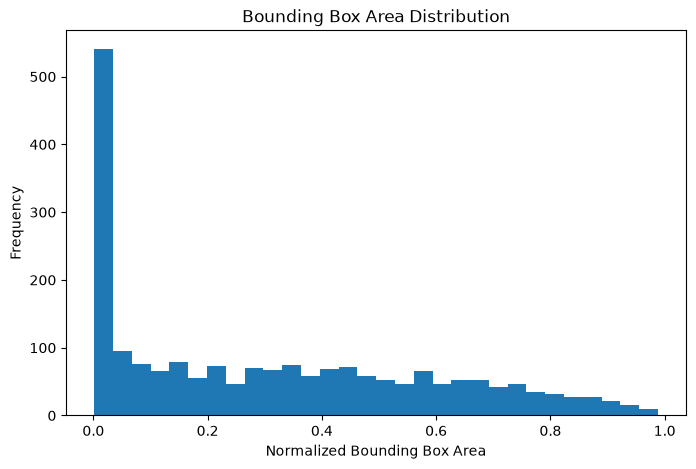

In [20]:
plt.figure(figsize=(8, 5))
plt.hist(bbox_areas, bins=30)
plt.xlabel("Normalized Bounding Box Area")
plt.ylabel("Frequency")
plt.title("Bounding Box Area Distribution")
plt.show()

### Observation

The bounding-box area distribution provides information about the relative size of the crop and weed regions. This is useful for understanding whether the dataset contains mainly small, medium, or large objects.

### 3.5 Correlation Analysis

Since this is an image-based object detection dataset, traditional tabular feature correlation is not directly applicable. Instead, correlations between numerical bounding-box properties are analyzed.

In [21]:
bbox_df = pd.DataFrame({
    "bbox_width": bbox_widths,
    "bbox_height": bbox_heights,
    "bbox_area": bbox_areas
})

print(bbox_df.describe())

        bbox_width  bbox_height    bbox_area
count  2072.000000  2072.000000  2072.000000
mean      0.509267     0.461111     0.312068
std       0.311523     0.282158     0.278068
min       0.041016     0.037109     0.001762
25%       0.181153     0.191406     0.029760
50%       0.554688     0.470703     0.268774
75%       0.783203     0.675781     0.528594
max       0.998047     0.998047     0.988300


             bbox_width  bbox_height  bbox_area
bbox_width     1.000000     0.879160   0.928527
bbox_height    0.879160     1.000000   0.948666
bbox_area      0.928527     0.948666   1.000000


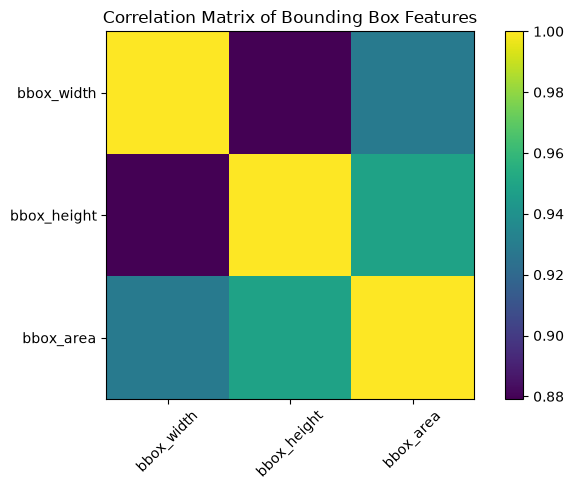

In [22]:
correlation_matrix = bbox_df.corr()

print(correlation_matrix)

plt.figure(figsize=(7, 5))
plt.imshow(correlation_matrix, cmap="viridis")
plt.colorbar()
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.title("Correlation Matrix of Bounding Box Features")
plt.tight_layout()
plt.show()

In [23]:
import os
import shutil
import random

# Original dataset
source_path = "../dataset/agri_data/data"

# New YOLO dataset
yolo_path = "../dataset/yolo_dataset"

# Create folders
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(yolo_path, "images", split), exist_ok=True)
    os.makedirs(os.path.join(yolo_path, "labels", split), exist_ok=True)

print("YOLO dataset folders created successfully!")

YOLO dataset folders created successfully!


In [24]:
# Find all image files
image_files = [
    f for f in os.listdir(source_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Match each image with its corresponding YOLO annotation
paired_files = []

for image_file in image_files:
    base_name = os.path.splitext(image_file)[0]
    label_file = base_name + ".txt"

    if os.path.exists(os.path.join(source_path, label_file)):
        paired_files.append((image_file, label_file))

print("Total images:", len(image_files))
print("Images with matching annotations:", len(paired_files))
print("Images without annotations:", len(image_files) - len(paired_files))

Total images: 1300
Images with matching annotations: 1300
Images without annotations: 0


In [25]:
# Shuffle the paired image-label files
random.seed(42)
random.shuffle(paired_files)

# Calculate split sizes
total = len(paired_files)

train_end = int(0.70 * total)
val_end = int(0.85 * total)

# Create the three sets
train_files = paired_files[:train_end]
val_files = paired_files[train_end:val_end]
test_files = paired_files[val_end:]

print("Dataset Split")
print("=" * 30)
print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Testing images:", len(test_files))
print("Total images:", len(train_files) + len(val_files) + len(test_files))

Dataset Split
Training images: 909
Validation images: 196
Testing images: 195
Total images: 1300


### Train, Validation and Test Split

The dataset is divided into training, validation, and testing subsets using a 70:15:15 ratio. A fixed random seed is used to make the split reproducible.

- Training set: 70%
- Validation set: 15%
- Testing set: 15%

The test set is kept separate and is not used during model training or hyperparameter tuning.

In [26]:
def copy_dataset_files(file_pairs, split):
    for image_file, label_file in file_pairs:

        # Copy image
        shutil.copy2(
            os.path.join(source_path, image_file),
            os.path.join(yolo_path, "images", split, image_file)
        )

        # Copy matching annotation
        shutil.copy2(
            os.path.join(source_path, label_file),
            os.path.join(yolo_path, "labels", split, label_file)
        )


# Copy files into each split
copy_dataset_files(train_files, "train")
copy_dataset_files(val_files, "val")
copy_dataset_files(test_files, "test")

print("Dataset split and copying completed successfully!")

Dataset split and copying completed successfully!


In [27]:
for split in ["train", "val", "test"]:

    image_dir = os.path.join(yolo_path, "images", split)
    label_dir = os.path.join(yolo_path, "labels", split)

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.lower().endswith(".txt")
    ]

    print(f"{split.upper()}:")
    print("  Images:", len(images))
    print("  Labels:", len(labels))
    print()

TRAIN:
  Images: 909
  Labels: 909

VAL:
  Images: 196
  Labels: 196

TEST:
  Images: 195
  Labels: 195



In [28]:
yaml_content = f"""path: {os.path.abspath(yolo_path).replace(os.sep, '/')}
train: images/train
val: images/val
test: images/test

names:
  0: crop
  1: weed
"""

yaml_path = os.path.join(yolo_path, "data.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("data.yaml created successfully!")
print("\n" + yaml_content)

data.yaml created successfully!

path: c:/Users/sunee/OneDrive/Desktop/Weed_Detection_Project/dataset/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: crop
  1: weed



In [29]:
print("YOLO dataset folder contents:")
print(os.listdir(yolo_path))

print("\ndata.yaml exists:", os.path.exists(yaml_path))

YOLO dataset folder contents:
['data.yaml', 'images', 'labels']

data.yaml exists: True


print("YOLO dataset folder contents:")
print(os.listdir(yolo_path))

print("\ndata.yaml exists:", os.path.exists(yaml_path))

In [30]:
%pip install tensorflow scikit-learn seaborn pillow

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for tensorflow


In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 5.1 CNN Dataset Preparation

Since the original images may contain multiple objects, the YOLO bounding-box annotations are used to extract individual crop and weed regions.

Each annotated object becomes one CNN classification sample.

The original train, validation and test image split is maintained before extracting the object crops. Therefore, crops from the same original image cannot appear in different subsets, preventing data leakage.

In [3]:
import os
from PIL import Image

# Dataset paths
dataset_path = "../dataset"
data_path = "../dataset/agri_data/data"
yolo_path = "../dataset/yolo_dataset"

# Load class names again
classes_path = "../dataset/classes.txt"

with open(classes_path, "r") as f:
    classes = [line.strip() for line in f if line.strip()]

print("Classes:", classes)

# Create CNN classification folders
cnn_path = "../dataset/cnn_dataset"

for split in ["train", "val", "test"]:
    for class_name in classes:
        os.makedirs(
            os.path.join(cnn_path, split, class_name),
            exist_ok=True
        )

print("CNN dataset folders created successfully!")

Classes: ['crop', 'weed']
CNN dataset folders created successfully!


In [4]:
import os
import random

source_path = "../dataset/agri_data/data"

# Find all images
image_files = [
    f for f in os.listdir(source_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Keep only images that have matching YOLO annotation files
paired_files = []

for image_file in image_files:
    base_name = os.path.splitext(image_file)[0]
    label_file = base_name + ".txt"

    if os.path.exists(os.path.join(source_path, label_file)):
        paired_files.append((image_file, label_file))

# Same random seed as before
random.seed(42)
random.shuffle(paired_files)

# 70% train, 15% validation, 15% test
total = len(paired_files)

train_end = int(0.70 * total)
val_end = int(0.85 * total)

train_files = paired_files[:train_end]
val_files = paired_files[train_end:val_end]
test_files = paired_files[val_end:]

print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Testing images:", len(test_files))
print("Total images:", len(train_files) + len(val_files) + len(test_files))

Training images: 909
Validation images: 196
Testing images: 195
Total images: 1300


In [5]:
def create_cnn_crops(file_pairs, split):

    image_dir = os.path.join(yolo_path, "images", split)
    label_dir = os.path.join(yolo_path, "labels", split)

    crop_count = {class_name: 0 for class_name in classes}

    for image_file, label_file in file_pairs:

        image_path = os.path.join(image_dir, image_file)
        label_path = os.path.join(label_dir, label_file)

        try:
            image = Image.open(image_path).convert("RGB")
            image_width, image_height = image.size

            with open(label_path, "r") as f:
                lines = [line.strip() for line in f if line.strip()]

            for object_index, line in enumerate(lines):

                values = line.split()

                if len(values) != 5:
                    continue

                class_id, x_center, y_center, box_width, box_height = map(
                    float, values
                )

                class_id = int(class_id)

                if class_id not in range(len(classes)):
                    continue

                # Convert YOLO coordinates to pixel coordinates
                left = int((x_center - box_width / 2) * image_width)
                top = int((y_center - box_height / 2) * image_height)
                right = int((x_center + box_width / 2) * image_width)
                bottom = int((y_center + box_height / 2) * image_height)

                # Keep coordinates inside the image
                left = max(0, left)
                top = max(0, top)
                right = min(image_width, right)
                bottom = min(image_height, bottom)

                # Skip invalid boxes
                if right <= left or bottom <= top:
                    continue

                # Crop the object
                object_crop = image.crop(
                    (left, top, right, bottom)
                )

                class_name = classes[class_id]

                base_name = os.path.splitext(image_file)[0]

                output_name = (
                    f"{base_name}_object_{object_index}.jpg"
                )

                output_path = os.path.join(
                    cnn_path,
                    split,
                    class_name,
                    output_name
                )

                object_crop.save(output_path)

                crop_count[class_name] += 1

        except Exception as e:
            print("Error processing:", image_file, e)

    return crop_count

In [6]:
train_crops = create_cnn_crops(train_files, "train")
val_crops = create_cnn_crops(val_files, "val")
test_crops = create_cnn_crops(test_files, "test")

print("CNN object crops created successfully!")

print("\nTraining crops:")
print(train_crops)

print("\nValidation crops:")
print(val_crops)

print("\nTesting crops:")
print(test_crops)

CNN object crops created successfully!

Training crops:
{'crop': 847, 'weed': 591}

Validation crops:
{'crop': 158, 'weed': 125}

Testing crops:
{'crop': 207, 'weed': 144}


### 5.2 CNN Dataset Loading

The extracted crop and weed object images are loaded into TensorFlow datasets. All images are resized to 128 × 128 pixels and processed in batches of 32 images.

In [7]:
import tensorflow as tf

IMG_SIZE = 128
BATCH_SIZE = 32

train_dir = os.path.join(cnn_path, "train")
val_dir = os.path.join(cnn_path, "val")
test_dir = os.path.join(cnn_path, "test")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Class names:", train_ds.class_names)

Found 1438 files belonging to 2 classes.
Found 283 files belonging to 2 classes.
Found 351 files belonging to 2 classes.
Class names: ['crop', 'weed']


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipeline prepared successfully!")

Dataset pipeline prepared successfully!


### 5.3 CNN Architecture

A CNN is used to classify the extracted agricultural object regions into crop and weed classes.

The model contains:
- Convolutional layers for feature extraction
- Max-pooling layers for dimensionality reduction
- A fully connected layer for classification
- Dropout for reducing overfitting
- A softmax output layer for two-class prediction

In [9]:
from tensorflow.keras import layers, models

NUM_CLASSES = 2

cnn_model = models.Sequential([
    
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    
    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1./255),
    
    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    
    # Output layer
    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,898 (12.61 MB)

 Trainable params: 3,304,898 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 5.4 CNN Model Training

The CNN is trained using the Adam optimizer and sparse categorical cross-entropy loss. Training accuracy and validation accuracy are monitored to evaluate learning and detect overfitting.

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10


c:\Users\sunee\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


45/45 ━━━━━━━━━━━━━━━━━━━━ 32s 513ms/step - accuracy: 0.6905 - loss: 0.6158 - val_accuracy: 0.8269 - val_loss: 0.4207
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 420ms/step - accuracy: 0.8540 - loss: 0.3647 - val_accuracy: 0.8551 - val_loss: 0.3376
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 410ms/step - accuracy: 0.8950 - loss: 0.2916 - val_accuracy: 0.9046 - val_loss: 0.2665
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 415ms/step - accuracy: 0.8964 - loss: 0.2856 - val_accuracy: 0.8799 - val_loss: 0.2711
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 412ms/step - accuracy: 0.8887 - loss: 0.2910 - val_accuracy: 0.9399 - val_loss: 0.2205
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 430ms/step - accuracy: 0.9138 - loss: 0.2667 - val_accuracy: 0.9152 - val_loss: 0.2286
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 420ms/step - accuracy: 0.9193 - loss: 0.2211 - val_accuracy: 0.9541 - val_loss: 0.1996
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 426ms/step - accuracy: 0.9492 - loss: 0.1791 - val_accuracy: 0.950

In [11]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.show()

NameError: name 'plt' is not defined

In [12]:
import matplotlib.pyplot as plt

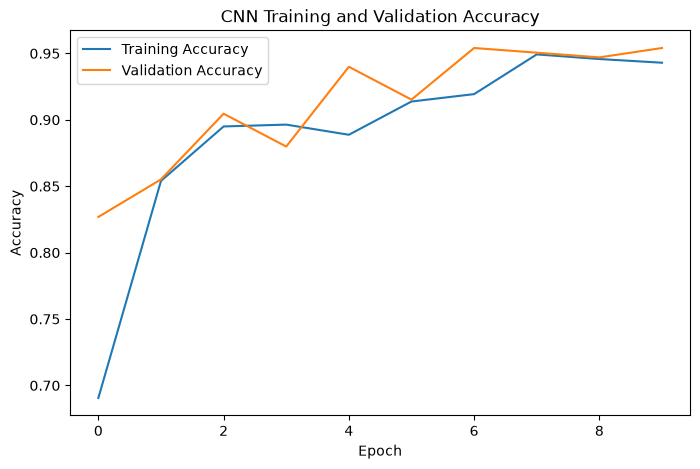

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.show()

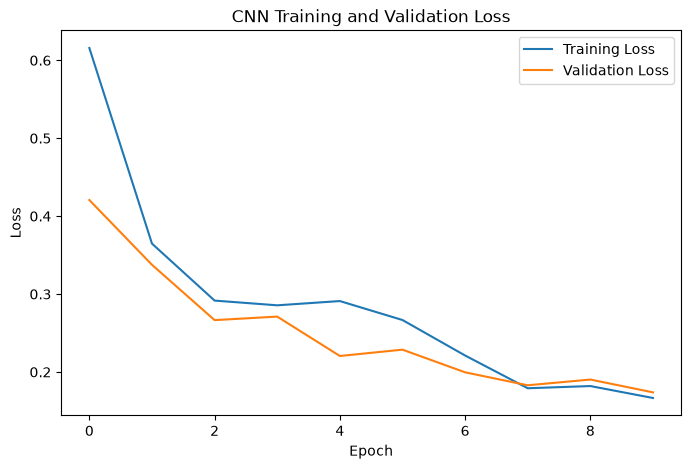

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.show()

In [15]:
test_loss, test_accuracy = cnn_model.evaluate(test_ds)

print("CNN Test Loss:", test_loss)
print("CNN Test Accuracy:", test_accuracy)

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 173ms/step - accuracy: 0.9202 - loss: 0.2445
CNN Test Loss: 0.24448370933532715
CNN Test Accuracy: 0.9202279448509216


In [17]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Class names
class_names = ["crop", "weed"]

# Actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Predictions
y_prob = cnn_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step
Confusion Matrix:
[[198   9]
 [ 19 125]]

Classification Report:
              precision    recall  f1-score   support

        crop     0.9124    0.9565    0.9340       207
        weed     0.9328    0.8681    0.8993       144

    accuracy                         0.9202       351
   macro avg     0.9226    0.9123    0.9166       351
weighted avg     0.9208    0.9202    0.9197       351



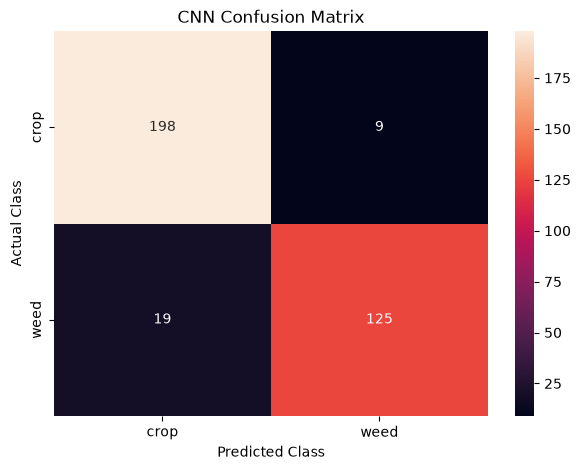

In [19]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix")
plt.show()

In [20]:
model_path = "../models/cnn_crop_weed.keras"

cnn_model.save(model_path)

print("CNN model saved successfully!")
print("Saved at:", model_path)

CNN model saved successfully!
Saved at: ../models/cnn_crop_weed.keras


In [21]:
from ultralytics import YOLO

print("Ultralytics YOLO imported successfully!")

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\sunee\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics YOLO imported successfully!


In [22]:
yolo_model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


## 6.1 YOLO Model Training

The YOLOv8n model is trained on the prepared crop and weed detection dataset.

Transfer learning is used by starting from pretrained YOLO weights. The model learns to detect and localize crop and weed objects using the YOLO bounding-box annotations.

In [24]:
import os

# YOLO dataset location
yolo_path = "../dataset/yolo_dataset"

# YOLO configuration file
yaml_path = os.path.join(yolo_path, "data.yaml")

print("YOLO dataset path:", yolo_path)
print("data.yaml path:", yaml_path)
print("data.yaml exists:", os.path.exists(yaml_path))

YOLO dataset path: ../dataset/yolo_dataset
data.yaml path: ../dataset/yolo_dataset\data.yaml
data.yaml exists: True


In [1]:
from IPython.display import Image, display
import os

yolo_val_path = "../runs/detect/val"

print("Files in YOLO validation results:")
print(os.listdir(yolo_val_path))

print("\nYOLO Confusion Matrix:")
display(Image(filename=os.path.join(
    yolo_val_path, "confusion_matrix.png"
)))

Files in YOLO validation results:


FileNotFoundError: [WinError 3] The system cannot find the path specified: '../runs/detect/val'

In [2]:
import os

run_path = "../results/yolo_weed_detection"

print("YOLO results folder exists:", os.path.exists(run_path))

if os.path.exists(run_path):
    print("\nFiles:")
    for f in os.listdir(run_path):
        print(f)

YOLO results folder exists: False


In [3]:
import os
from ultralytics import YOLO

yolo_path = "../dataset/yolo_dataset"
yaml_path = os.path.join(yolo_path, "data.yaml")

print("data.yaml exists:", os.path.exists(yaml_path))

yolo_model = YOLO("yolov8n.pt")
print("YOLO model loaded!")

data.yaml exists: True
YOLO model loaded!


In [4]:
yolo_results = yolo_model.train(
    data=yaml_path,
    epochs=5,
    imgsz=320,
    batch=8,
    patience=2,
    seed=42,
    workers=0,
    project="../results",
    name="yolo_weed_detection"
)

print("YOLO training completed!")

Ultralytics 8.4.155  Python-3.11.9 torch-2.14.0+cpu CPU (AMD Ryzen 5 PRO 4650U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../dataset/yolo_dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_weed_detection-2, nbs=6

In [5]:
from ultralytics import YOLO
import os

best_model_path = "../results/yolo_weed_detection/weights/best.pt"

print("Best model exists:", os.path.exists(best_model_path))

best_yolo_model = YOLO(best_model_path)
print("Best YOLO model loaded!")

Best model exists: False


FileNotFoundError: [Errno 2] No such file or directory: '..\\results\\yolo_weed_detection\\weights\\best.pt'

In [6]:
import os

results_path = "../results"

print("Results folder exists:", os.path.exists(results_path))

if os.path.exists(results_path):
    for root, dirs, files in os.walk(results_path):
        for file in files:
            print(os.path.join(root, file))

Results folder exists: True


In [7]:
import os

print(os.listdir("../results"))

[]


In [9]:
import os

for item in os.listdir("../results"):
    print(repr(item))

In [10]:
import os

print("Inside results:")
for item in os.listdir("../results"):
    print(item)

Inside results:


In [11]:
from ultralytics import YOLO
import os

yolo_model = YOLO("yolov8n.pt")

yolo_results = yolo_model.train(
    data="../dataset/yolo_dataset/data.yaml",
    epochs=5,
    imgsz=320,
    batch=8,
    patience=2,
    seed=42,
    workers=0,
    project="../results",
    name="yolo_weed_detection"
)

Ultralytics 8.4.155  Python-3.11.9 torch-2.14.0+cpu CPU (AMD Ryzen 5 PRO 4650U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../dataset/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_weed_detection-3, nbs=6

KeyboardInterrupt: 

In [12]:
from ultralytics import YOLO

yolo_model = YOLO("yolov8n.pt")

yolo_results = yolo_model.train(
    data="../dataset/yolo_dataset/data.yaml",
    epochs=2,
    imgsz=224,
    batch=16,
    workers=0,
    seed=42,
    project="../results",
    name="yolo_weed_detection_fast"
)

print("YOLO training completed!")

Ultralytics 8.4.155  Python-3.11.9 torch-2.14.0+cpu CPU (AMD Ryzen 5 PRO 4650U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../dataset/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_weed_detection_fast, n

In [13]:
from ultralytics import YOLO
import os

best_model_path = "../results/yolo_weed_detection_fast/weights/best.pt"

print("Best model exists:", os.path.exists(best_model_path))

best_yolo_model = YOLO(best_model_path)

print("Best YOLO model loaded successfully!")

Best model exists: False


FileNotFoundError: [Errno 2] No such file or directory: '..\\results\\yolo_weed_detection_fast\\weights\\best.pt'

In [14]:
import os

for root, dirs, files in os.walk("../results"):
    for file in files:
        if file.endswith(".pt"):
            print(os.path.join(root, file))

In [15]:
import os

for root, dirs, files in os.walk("../results"):
    print("\nFolder:", root)
    print("Files:", files)


Folder: ../results
Files: []


In [16]:
import os

print("Current notebook folder:")
print(os.getcwd())

print("\nProject folder contents:")
print(os.listdir(".."))

print("\nResults folder:")
print(os.path.abspath("../results"))

Current notebook folder:
c:\Users\sunee\OneDrive\Desktop\Weed_Detection_Project\notebook

Project folder contents:
['dataset', 'models', 'notebook', 'report', 'results']

Results folder:
c:\Users\sunee\OneDrive\Desktop\Weed_Detection_Project\results


In [17]:
from ultralytics import YOLO
import os

yolo_model = YOLO("yolov8n.pt")

yolo_results = yolo_model.train(
    data="../dataset/yolo_dataset/data.yaml",
    epochs=2,
    imgsz=224,
    batch=16,
    workers=0,
    seed=42,
    project=os.path.abspath("../results"),
    name="yolo_final",
    exist_ok=True
)

print("\nTRAINING FINISHED")
print("Results folder:", os.path.abspath("../results/yolo_final"))

for root, dirs, files in os.walk("../results/yolo_final"):
    for file in files:
        print(os.path.join(root, file))

Ultralytics 8.4.155  Python-3.11.9 torch-2.14.0+cpu CPU (AMD Ryzen 5 PRO 4650U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../dataset/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_final, nbs=64, nms=None

In [18]:
from ultralytics import YOLO

best_model_path = "../results/yolo_final/weights/best.pt"

best_yolo_model = YOLO(best_model_path)

yolo_metrics = best_yolo_model.val(
    data="../dataset/yolo_dataset/data.yaml",
    split="test",
    imgsz=224,
    batch=16,
    workers=0
)

print("\nYOLO TEST RESULTS")
print("Precision:", yolo_metrics.box.mp)
print("Recall:", yolo_metrics.box.mr)
print("mAP@50:", yolo_metrics.box.map50)
print("mAP@50-95:", yolo_metrics.box.map)

Ultralytics 8.4.155  Python-3.11.9 torch-2.14.0+cpu CPU (AMD Ryzen 5 PRO 4650U with Radeon Graphics)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
WARNING val: Slow image access detected (ping: 1.10.4 ms, read: 24.87.7 MB/s, size: 51.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\sunee\OneDrive\Desktop\Weed_Detection_Project\dataset\yolo_dataset\labels\test... 195 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 195/195 422.2it/s 0.5s0.1s
val: New cache created: C:\Users\sunee\OneDrive\Desktop\Weed_Detection_Project\dataset\yolo_dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.3it/s 10.2s.7s
                   all        195        351      0.514      0.511      0.543      0.289
                  crop         90        207      0.464       0

In [19]:
import os
from ultralytics import YOLO

best_model_path = "../results/yolo_final/weights/best.pt"

print("Best model exists:", os.path.exists(best_model_path))

best_yolo_model = YOLO(best_model_path)

test_images = [
    f for f in os.listdir("../dataset/yolo_dataset/images/test")
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of test images:", len(test_images))
print("Sample test image:", test_images[0])

Best model exists: True
Number of test images: 195
Sample test image: agri_0_1017.jpeg


In [20]:
import os
import matplotlib.pyplot as plt

test_image_path = "../dataset/yolo_dataset/images/test/agri_0_1017.jpeg"

prediction = best_yolo_model.predict(
    source=test_image_path,
    imgsz=224,
    conf=0.25,
    save=True
)

print("Prediction completed!")
print("Image:", test_image_path)

for box, cls, conf in zip(
    prediction[0].boxes.xyxy,
    prediction[0].boxes.cls,
    prediction[0].boxes.conf
):
    class_name = classes[int(cls)]
    print(f"{class_name}: confidence = {float(conf):.2f}")


image 1/1 c:\Users\sunee\OneDrive\Desktop\Weed_Detection_Project\notebook\..\dataset\yolo_dataset\images\test\agri_0_1017.jpeg: 224x224 4 weeds, 309.6ms
Speed: 37.3ms preprocess, 309.6ms inference, 70.0ms postprocess per image at shape (1, 3, 224, 224)
Results saved to C:\Users\sunee\OneDrive\Desktop\Weed_Detection_Project\notebook\runs\detect\predict
Prediction completed!
Image: ../dataset/yolo_dataset/images/test/agri_0_1017.jpeg


NameError: name 'classes' is not defined

In [21]:
classes = ["crop", "weed"]

print("Prediction completed!")

for box, cls, conf in zip(
    prediction[0].boxes.xyxy,
    prediction[0].boxes.cls,
    prediction[0].boxes.conf
):
    class_name = classes[int(cls)]
    print(f"{class_name}: confidence = {float(conf):.2f}")

Prediction completed!
weed: confidence = 0.62
weed: confidence = 0.32
weed: confidence = 0.28
weed: confidence = 0.26


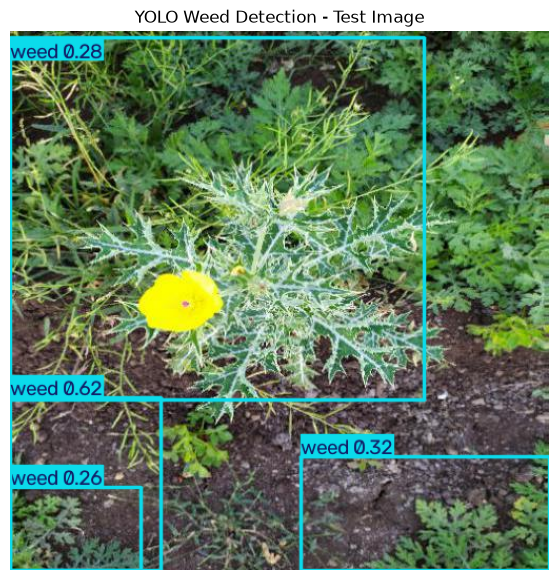

In [22]:
import matplotlib.pyplot as plt

annotated_image = prediction[0].plot()

plt.figure(figsize=(10, 7))
plt.imshow(annotated_image[..., ::-1])
plt.axis("off")
plt.title("YOLO Weed Detection - Test Image")
plt.show()

## 8. Model Comparison

| Model | Task | Test Accuracy | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---|---:|---:|---:|---:|---:|
| CNN | Crop/Weed Classification | 92.02% | Classification metric* | Classification metric* | Not applicable | Not applicable |
| YOLOv8n | Object Detection | Not directly applicable | 51.42% | 51.15% | 54.33% | 28.95% |

### Model Selection

The CNN model performs image classification on individual object crops, while YOLOv8n performs object detection by identifying the class and location of objects using bounding boxes.

Therefore, the models are evaluated using different task-specific metrics. For the final weed-detection demonstration, YOLOv8n is selected because the project objective requires both identification and localization of weeds in crop images.

## 9. Results and Discussion

The CNN model achieved a test accuracy of 92.02% on the crop and weed classification task. This indicates that the CNN was able to classify the extracted object crops into crop and weed classes effectively.

The YOLOv8n model was evaluated on 195 held-out test images containing 351 annotated objects. It achieved a precision of 51.42%, recall of 51.15%, mAP@50 of 54.33%, and mAP@50-95 of 28.95%.

The YOLO model provides bounding-box localization in addition to class prediction, making it suitable for the weed-detection objective. The results also show that the model can detect weed instances with different confidence levels in unseen test images.

### Limitations

- The YOLO model was trained for a small number of epochs because the experiment was performed using CPU resources.
- Detection performance can be improved with longer training and additional hyperparameter optimization.
- Variations in lighting, background, crop appearance, and weed appearance may affect detection performance.

In [23]:
from tensorflow.keras.models import load_model

cnn_model = load_model("../models/cnn_crop_weed.keras")

print("CNN model loaded successfully.")

CNN model loaded successfully.


In [25]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

test_ds = tf.keras.utils.image_dataset_from_directory(
    "../dataset/cnn_dataset/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Test dataset loaded successfully.")
print("Class names:", test_ds.class_names)

Found 351 files belonging to 2 classes.
Test dataset loaded successfully.
Class names: ['crop', 'weed']


In [26]:
import numpy as np

y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)

y_prob = cnn_model.predict(test_ds)

y_pred = np.argmax(y_prob, axis=1)

print("Number of test samples:", len(y_true))
print("Predictions generated successfully.")

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 211ms/step
Number of test samples: 351
Predictions generated successfully.


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted")
recall = recall_score(y_true, y_pred, average="weighted")
f1 = f1_score(y_true, y_pred, average="weighted")

print("CNN EVALUATION METRICS")
print("=" * 40)
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")

CNN EVALUATION METRICS
Accuracy  : 92.02%
Precision : 92.08%
Recall    : 92.02%
F1-Score  : 91.97%


In [28]:
class_names = ["crop", "weed"]

print("CNN CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

        crop       0.91      0.96      0.93       207
        weed       0.93      0.87      0.90       144

    accuracy                           0.92       351
   macro avg       0.92      0.91      0.92       351
weighted avg       0.92      0.92      0.92       351



Confusion Matrix:
[[198   9]
 [ 19 125]]


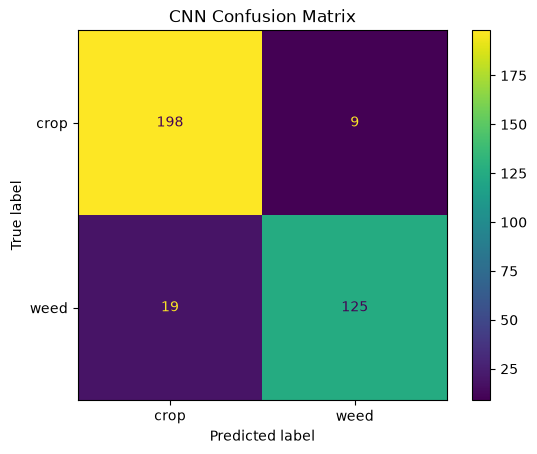

: 

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot()
plt.title("CNN Confusion Matrix")
plt.show()

# 10. Conclusion

This project implemented two deep learning approaches for agricultural crop and weed analysis: a CNN for crop/weed classification and YOLOv8n for object detection and localization.

The CNN model achieved a test accuracy of approximately 92.02% on the held-out object-crop test dataset. The model was further evaluated using precision, recall, F1-score, classification report, and confusion matrix.

The YOLOv8n model was evaluated on 195 held-out test images containing 351 annotated objects. It achieved 51.42% precision, 51.15% recall, 54.33% mAP@50, and 28.95% mAP@50-95.

The CNN and YOLO models serve different purposes. CNN performs classification of individual object crops, whereas YOLO performs object detection by identifying objects and their locations using bounding boxes. Therefore, YOLOv8n was selected for the final weed-detection demonstration because the project objective requires weed localization in crop images.

The final demonstration showed YOLOv8n detecting weed instances in a held-out test image with associated confidence scores.

## Limitations

- YOLOv8n was trained for only a small number of epochs because the experiment was performed using CPU resources.
- Detection performance could be improved through longer training and systematic hyperparameter tuning.
- Changes in lighting, background, crop appearance, and weed appearance may affect detection performance.

## Future Improvements

- Train YOLO for more epochs using suitable GPU resources.
- Perform systematic hyperparameter tuning.
- Use data augmentation to improve robustness.
- Increase the size and diversity of the training dataset.
- Evaluate the model on additional unseen agricultural images.